# Parte 5: Seleção de Features

Avaliação do impacto da seleção de features no desempenho da classificação, usando os métodos de
regularização Ridge, Lasso e Elastic Net, conforme pedido na secção 5 do enunciado.

### Índice

1. Enquadramento
2. Preparação dos dados
3. Os três modelos regularizados
4. Exploração de diferentes valores de C
5. Escolha de C por validação cruzada
6. Coeficientes e variáveis selecionadas
7. Conjunto completo versus conjuntos reduzidos
8. Efeito do balanceamento das classes
9. Discussão
10. Conclusões
11. Referências

## 1. Enquadramento

A regularização acrescenta um termo de penalização à função de perda do modelo. Na regressão linear a
perda de base é a soma dos quadrados dos resíduos e na regressão logística é o simétrico da
log-verosimilhança. As penalizações são as mesmas nos dois casos:

| Modelo | Penalização | Parâmetro `l1_ratio` | Anula coeficientes |
|---|---|---|---|
| Ridge | λ Σ βⱼ² , norma L2 | 0 | Não |
| Lasso | λ Σ \|βⱼ\| , norma L1 | 1 | Sim |
| Elastic Net | mistura das duas | entre 0 e 1 | Sim |

A partir da versão 1.8 do scikit-learn, a penalização é especificada pelo parâmetro `l1_ratio`:
- `l1_ratio` = 0: Ridge puro (apenas $L_2$).
- `l1_ratio` = 1: Lasso puro (apenas $L_1$).
- `l1_ratio` = 0.5: Mistura equilibrada de 50/50.

A intensidade da penalização é dada por `C`, que é o
**inverso de λ**: valores pequenos de `C` significam penalização forte.

O alvo é `target_class`, variável qualitativa com três categorias. A variável `target_regression` é o
alvo da tarefa de regressão e fica excluída dos preditores.

## 2. Preparação dos dados

Carregam-se os dados e removem-se as três colunas que a análise exploratória identificou como
inutilizáveis: `calcium_baseline`, que é constante, `systolic_index`, que duplica `systolic_bp`, e
`age_normalized`, que é uma reescala de `age`.

A divisão em treino e teste é **estratificada**, o que preserva as proporções das três classes em ambas
as partições. Isto é importante porque a classe `DI_HT` tem apenas 85 registos no total.

Por fim, as variáveis são padronizadas com `StandardScaler`. Este passo é obrigatório, pois o termo de
penalização é sensível à escala e, sem ele, variáveis com valores maiores seriam penalizadas mais do
que as outras apenas por causa das unidades. O escalador é **ajustado apenas no conjunto de treino** e
depois aplicado ao de teste, para que nenhuma informação do teste influencie o modelo.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42
print('scikit-learn:', sklearn.__version__)

nome_ficheiro = 'dataset_grupo_22.csv'
caminhos = [Path.cwd() / nome_ficheiro, Path.cwd().parent / nome_ficheiro]
caminho = next((p for p in caminhos if p.is_file()), None)
if caminho is None:
    raise FileNotFoundError(f'Nao foi encontrado {nome_ficheiro}.')

df = pd.read_csv(caminho)
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

# Colunas removidas com base na analise exploratoria (constante e redundantes)
REMOVIDAS = ['calcium_baseline', 'age_normalized', 'systolic_index']

num_cols = [c for c in df.select_dtypes(include='number').columns
            if c not in REMOVIDAS + [TARGET_REG]]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

# Codificacao das categoricas em colunas binarias
X = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True)
y = df[TARGET_CLS]
colunas = list(X.columns)
classes = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# Padronizacao: ajustada no treino, aplicada ao teste
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f'Variaveis originais: {len(num_cols)} numericas + {len(cat_cols)} categoricas '
      f'= {len(num_cols) + len(cat_cols)}')
print(f'Colunas apos get_dummies: {len(colunas)}')
print(f'Treino: {len(X_train)} | Teste: {len(X_test)}')
print('\nDistribuicao das classes (treino / teste, em %):')
print(pd.DataFrame({'treino': y_train.value_counts(normalize=True) * 100,
                    'teste': y_test.value_counts(normalize=True) * 100}).round(2))

scikit-learn: 1.9.1
Variaveis originais: 18 numericas + 12 categoricas = 30
Colunas apos get_dummies: 40
Treino: 1500 | Teste: 500

Distribuicao das classes (treino / teste, em %):
              treino   teste
target_class                
DI_HY        89.8700 90.0000
HT            5.8700  5.8000
DI_HT         4.2700  4.2000


**Conclusões:** Ficam 30 variáveis originais, 18 numéricas e 12 categóricas, que após a codificação dão
origem a 40 colunas.

A estratificação funcionou. As proporções das três classes são praticamente idênticas no treino e no
teste, mantendo o desequilíbrio original de cerca de 90, 6 e 4 por cento.

## 3. Os três modelos regularizados

Os parâmetros principais da `LogisticRegression` são:

- **`solver='saga'`**, o algoritmo de otimização, e o único que suporta as três penalizações;
- **`l1_ratio`**, que escolhe a penalização, com 0 para Ridge, 1 para Lasso e 0.5 para Elastic Net;
- **`C`**, a intensidade da regularização, inversa de λ;
- **`max_iter`**, o número máximo de iterações permitidas ao algoritmo.

Ajustam-se primeiro os três modelos com `C = 1`, um valor intermédio da escala, para observar o
comportamento base antes de qualquer afinação. Como as classes estão desequilibradas, reporta-se a
*accuracy*, mas também o **F1 macro** e a **balanced accuracy**, que atribuem igual peso às três
classes.

In [2]:
MODELOS = [('Ridge', 0.0), ('Lasso', 1.0), ('Elastic Net', 0.5)]

def magnitudes(modelo):
    """Maior coeficiente absoluto de cada coluna, considerando as tres classes."""
    return np.abs(modelo.coef_).max(axis=0)

def metricas(modelo, X_esc, nome, extra=None):
    previsto = modelo.predict(X_esc)
    resultado = {'modelo': nome,
                 'accuracy': accuracy_score(y_test, previsto),
                 'F1 macro': f1_score(y_test, previsto, average='macro'),
                 'balanced acc': balanced_accuracy_score(y_test, previsto)}
    if extra:
        resultado.update(extra)
    return resultado

linhas = []
for nome, ratio in MODELOS:
    modelo = LogisticRegression(solver='saga', l1_ratio=ratio, C=1.0,
                                max_iter=10000, random_state=RANDOM_STATE)
    modelo.fit(X_train_esc, y_train)
    linhas.append(metricas(modelo, X_test_esc, nome,
                           {'l1_ratio': ratio, 'C': 1.0,
                            'nao nulos': int((magnitudes(modelo) > 1e-4).sum())}))

pd.DataFrame(linhas).set_index('modelo')[['l1_ratio', 'C', 'accuracy',
                                          'F1 macro', 'balanced acc', 'nao nulos']]

,l1_ratio,C,accuracy,F1 macro,balanced acc,nao nulos
modelo,,,,,,
Ridge,0.0000,1.0000,0.9460,0.6801,0.6539,40
Lasso,1.0000,1.0000,0.9440,0.6579,0.6380,37
Elastic Net,0.5000,1.0000,0.9460,0.6801,0.6539,39


**Conclusões:** Com `C = 1`, o Ridge e o Elastic Net atingem 0.9460 de *accuracy* e o Lasso 0.9440. A
diferença relevante está no número de coeficientes não nulos: o Lasso anula três das 40 colunas e o
Elastic Net uma, enquanto o Ridge mantém todas. É exatamente o comportamento previsto pela teoria.

A *accuracy* acima de 0.94 parece excelente, mas o F1 macro fica entre 0.66 e 0.68 e a balanced
accuracy em cerca de 0.65. A distância entre estas métricas revela que o modelo acerta sobretudo na
classe maioritária, o que confirma a importância de não avaliar este problema apenas pela *accuracy*.

## 4. Exploração de diferentes valores de C

Para compreender o efeito da regularização é necessário observar como o modelo se comporta ao longo de
toda a gama de penalizações, e não apenas num valor isolado. Percorrem-se por isso doze valores de `C`
numa escala logarítmica entre 0.001 e 100, usando o Lasso por ser a penalização que anula coeficientes.

Para cada valor registam-se o número de colunas não nulas, o número de variáveis originais retidas e o
desempenho no conjunto de teste.

In [3]:
GRELHA_C = np.logspace(-3, 2, 12)

def variaveis_retidas(modelo, nomes_colunas):
    """Converte colunas nao nulas em variaveis originais."""
    valores = magnitudes(modelo)
    vivas = {nomes_colunas[i] for i in range(len(nomes_colunas)) if valores[i] > 1e-4}
    numericas = [c for c in num_cols if c in vivas]
    categoricas = [c for c in cat_cols
                   if any(v.startswith(c + '_') for v in vivas)]
    return numericas, categoricas, len(vivas)

percurso = []
for C in GRELHA_C:
    modelo = LogisticRegression(solver='saga', l1_ratio=1.0, C=C,
                                max_iter=10000, random_state=RANDOM_STATE)
    modelo.fit(X_train_esc, y_train)
    retidas_num, retidas_cat, n_colunas = variaveis_retidas(modelo, colunas)
    previsto = modelo.predict(X_test_esc)
    percurso.append({'C': C,
                     'colunas nao nulas': n_colunas,
                     'variaveis retidas': len(retidas_num) + len(retidas_cat),
                     'accuracy': accuracy_score(y_test, previsto),
                     'F1 macro': f1_score(y_test, previsto, average='macro')})

percurso = pd.DataFrame(percurso)
percurso

,C,colunas nao nulas,variaveis retidas,accuracy,F1 macro
0,0.0010,0,0,0.9000,0.3158
1,0.0028,0,0,0.9000,0.3158
2,0.0081,2,2,0.9140,0.4478
3,0.0231,3,3,0.9360,0.5772
4,0.0658,14,13,0.9360,0.5885
5,0.1874,28,21,0.9420,0.6458
6,0.5337,33,24,0.9400,0.6432
7,1.5199,38,29,0.9460,0.6801
8,4.3288,40,30,0.9460,0.6774
9,12.3285,40,30,0.9460,0.6774


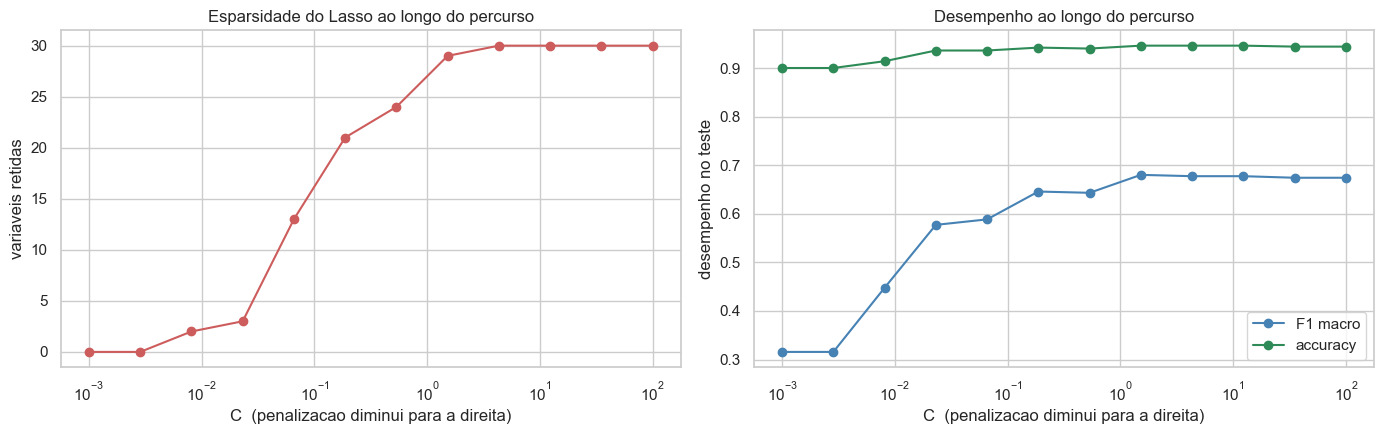

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(percurso['C'], percurso['variaveis retidas'], 'o-', color='indianred')
ax1.set_xscale('log'); ax1.set_xlabel('C  (penalizacao diminui para a direita)')
ax1.set_ylabel('variaveis retidas')
ax1.set_title('Esparsidade do Lasso ao longo do percurso')

ax2.plot(percurso['C'], percurso['F1 macro'], 'o-', color='steelblue', label='F1 macro')
ax2.plot(percurso['C'], percurso['accuracy'], 'o-', color='seagreen', label='accuracy')
ax2.set_xscale('log'); ax2.set_xlabel('C  (penalizacao diminui para a direita)')
ax2.set_ylabel('desempenho no teste')
ax2.set_title('Desempenho ao longo do percurso'); ax2.legend()

plt.tight_layout(); plt.show()

**Conclusões:** O percurso mostra com clareza o compromisso entre simplicidade e desempenho.

Com penalização muito forte, `C` igual a 0.001, todos os coeficientes são anulados e o modelo colapsa
para a previsão da classe maioritária, com F1 macro de 0.3158. À medida que `C` aumenta, as variáveis
entram por ordem de importância: duas em `C` igual a 0.008, três em 0.023, treze em 0.066, vinte e uma
em 0.187 e a totalidade a partir de `C` igual a 4.33.

O desempenho sobe rapidamente e depois estabiliza. Com treze variáveis o F1 macro atinge 0.5885, e com
vinte e uma chega a 0.6458, sendo o máximo 0.6801.

## 5. Escolha de C por validação cruzada

A secção anterior avaliou cada `C` no conjunto de teste, o que serve para ilustrar o comportamento mas
não é adequado para escolher o hiperparâmetro, pois usaria os dados de teste na decisão.

A escolha correta faz-se por **validação cruzada estratificada em 5 partições**, aplicada apenas ao
conjunto de treino. Para cada valor de `C`, o modelo é ajustado cinco vezes, deixando de fora uma
partição de cada vez, e regista-se a média do F1 macro obtido nas partições deixadas de fora.

O ciclo é escrito explicitamente por uma razão importante. **A padronização tem de ser feita dentro de
cada partição**, ajustando o escalador apenas às quatro partições de treino e aplicando-o à partição
de validação. Se as médias e os desvios-padrão fossem calculados sobre a totalidade do conjunto de
treino, a partição de validação contribuiria para as estatísticas usadas no seu próprio modelo, o que
constitui fuga de informação. O conjunto de teste só é usado no fim, para verificação independente.

In [5]:
def avaliar_cv(l1_ratio, C, X_treino_df, y_treino, class_weight=None):
    """Validacao cruzada estratificada, padronizando dentro de cada particao."""
    pontuacoes = []
    for idx_treino, idx_validacao in cv.split(X_treino_df, y_treino):
        X_a = X_treino_df.iloc[idx_treino]
        X_b = X_treino_df.iloc[idx_validacao]
        y_a = y_treino.iloc[idx_treino]
        y_b = y_treino.iloc[idx_validacao]

        escala = StandardScaler()
        X_a_esc = escala.fit_transform(X_a)   
        X_b_esc = escala.transform(X_b)       

        modelo = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=C,
                                    max_iter=10000, class_weight=class_weight,
                                    random_state=RANDOM_STATE)
        modelo.fit(X_a_esc, y_a)
        pontuacoes.append(f1_score(y_b, modelo.predict(X_b_esc), average='macro'))
    return float(np.mean(pontuacoes)), float(np.std(pontuacoes))

def afinar(l1_ratio, X_treino_df, class_weight=None):
    """Percorre a grelha de C, escolhe o melhor e reajusta no treino completo."""
    avaliacoes = [(C,) + avaliar_cv(l1_ratio, C, X_treino_df, y_train, class_weight)
                  for C in GRELHA_C]
    melhor_C, media, desvio = max(avaliacoes, key=lambda linha: linha[1])

    escala = StandardScaler()
    X_esc = escala.fit_transform(X_treino_df)
    modelo = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=melhor_C,
                                max_iter=10000, class_weight=class_weight,
                                random_state=RANDOM_STATE).fit(X_esc, y_train)
    return {'C': melhor_C, 'f1_cv': media, 'desvio_cv': desvio,
            'modelo': modelo, 'escala': escala}

def resumo(ajuste, nome, X_teste_df, nomes_colunas, k):
    previsto = ajuste['modelo'].predict(ajuste['escala'].transform(X_teste_df))
    recalls = recall_score(y_test, previsto, average=None, labels=classes)
    _, _, n_colunas = variaveis_retidas(ajuste['modelo'], nomes_colunas)
    return {'modelo': nome, 'k': k, 'C*': ajuste['C'],
            'F1 macro (CV)': ajuste['f1_cv'],
            'desvio (CV)': ajuste['desvio_cv'],
            'F1 macro (teste)': f1_score(y_test, previsto, average='macro'),
            'accuracy': accuracy_score(y_test, previsto),
            'balanced acc': balanced_accuracy_score(y_test, previsto),
            'colunas nao nulas': n_colunas,
            **{f'recall {c}': r for c, r in zip(classes, recalls)}}

ajustes = {nome: afinar(ratio, X_train) for nome, ratio in MODELOS}

pd.DataFrame([resumo(a, nome, X_test, colunas, len(num_cols) + len(cat_cols))
              for nome, a in ajustes.items()]).set_index('modelo')

,k,C*,F1 macro (CV),desvio (CV),F1 macro (teste),accuracy,balanced acc,colunas nao nulas,recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,,,
Ridge,30,1.5199,0.6185,0.0405,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Lasso,30,4.3288,0.6232,0.0416,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Elastic Net,30,1.5199,0.6197,0.0381,0.6801,0.9460,0.6539,40,0.1429,0.9911,0.8276


**Conclusões:** O Lasso obtém o melhor F1 macro em validação cruzada, 0.6232, com `C` igual a 4.33. O
Elastic Net fica em 0.6197 e o Ridge em 0.6185, ambos com `C` igual a 1.52. As diferenças entre os três
são inferiores a 0.005, valor muito abaixo da variação entre partições, pelo que nenhum é claramente
superior aos outros.

Em todos eles o `C` escolhido corresponde a uma penalização fraca, e por isso nenhuma variável é
eliminada. Isto acontece porque a penalização que maximiza o desempenho é insuficiente para anular
coeficientes. Para obter um conjunto efetivamente reduzido é necessário impor uma penalização mais
forte, o que se faz na secção 7.

## 6. Coeficientes e variáveis selecionadas

Comparam-se as magnitudes dos coeficientes das três penalizações no valor de `C` escolhido. Como o
problema tem três classes, o modelo estima uma matriz de coeficientes com uma linha por classe.

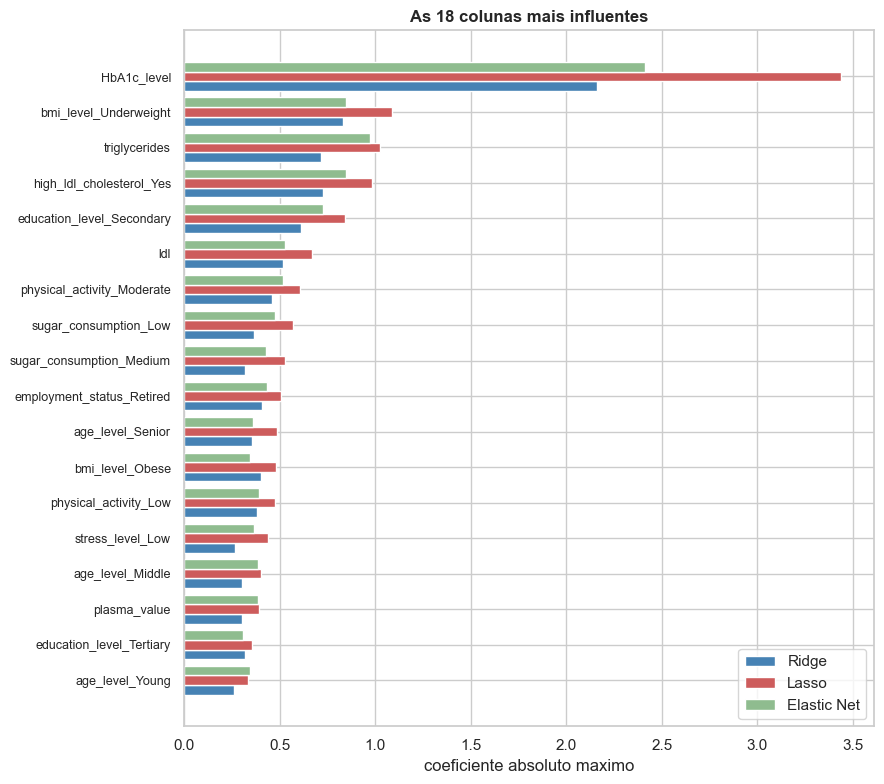

,Ridge,Lasso,Elastic Net
HbA1c_level,2.1618,3.4392,2.4106
bmi_level_Underweight,0.8295,1.0878,0.8462
triglycerides,0.7169,1.0273,0.9718
high_ldl_cholesterol_Yes,0.7257,0.9812,0.8485
education_level_Secondary,0.6108,0.8429,0.7276
ldl,0.5195,0.6716,0.5290
physical_activity_Moderate,0.4578,0.6064,0.5166
sugar_consumption_Low,0.3645,0.5687,0.4755
sugar_consumption_Medium,0.3209,0.5275,0.4291
employment_status_Retired,0.4088,0.5087,0.4315


In [6]:
tabela_coef = pd.DataFrame(
    {nome: magnitudes(a['modelo']) for nome, a in ajustes.items()},
    index=colunas
).sort_values('Lasso', ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
topo = tabela_coef.head(18).iloc[::-1]
posicao = np.arange(len(topo))
for deslocamento, nome, cor in [(-0.27, 'Ridge', 'steelblue'),
                                (0.0, 'Lasso', 'indianred'),
                                (0.27, 'Elastic Net', 'darkseagreen')]:
    ax.barh(posicao + deslocamento, topo[nome], height=0.27, label=nome, color=cor)
ax.set_yticks(posicao); ax.set_yticklabels(topo.index, fontsize=9)
ax.set_xlabel('coeficiente absoluto maximo')
ax.set_title('As 18 colunas mais influentes', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

tabela_coef.round(4).head(12)

**Conclusões:** As três penalizações concordam na ordenação. A variável `HbA1c_level` domina de forma
destacada, seguida de indicadores derivados do índice de massa corporal e de `triglycerides`.

Esta hierarquia coincide com a que a análise exploratória tinha estabelecido por via estatística,
através dos testes de Kruskal-Wallis, nos quais `HbA1c_level` e `triglycerides` apresentaram os maiores
tamanhos de efeito. Dois métodos independentes, identificam as mesmas variáveis como relevantes.

## 7. Conjunto completo vs. conjuntos reduzidos

Para responder à comparação pedida pelo enunciado, usam-se como conjuntos reduzidos aqueles que o
próprio Lasso seleciona em penalizações mais fortes, identificados no percurso da secção 4. Escolhem-se
dois pontos, um intermédio com vinte e uma variáveis e um agressivo com treze, o que permite medir o
custo de cada grau de simplificação.

Cada conjunto é avaliado com as três penalizações, com o `C` novamente escolhido por validação
cruzada e a padronização refeita dentro de cada partição, para que a comparação seja justa.

In [7]:
def colunas_das_variaveis(variaveis_num, variaveis_cat):
    """Colunas codificadas que correspondem a um conjunto de variaveis originais."""
    return [c for c in colunas
            if c in variaveis_num or any(c.startswith(k + '_') for k in variaveis_cat)]

def selecao_do_lasso(C):
    modelo = LogisticRegression(solver='saga', l1_ratio=1.0, C=C,
                                max_iter=10000, random_state=RANDOM_STATE)
    modelo.fit(X_train_esc, y_train)
    retidas_num, retidas_cat, _ = variaveis_retidas(modelo, colunas)
    return retidas_num, retidas_cat

red21_num, red21_cat = selecao_do_lasso(0.1874)
red13_num, red13_cat = selecao_do_lasso(0.0658)

CONJUNTOS = {
    'Completo': (num_cols, cat_cols),
    'Reduzido (21)': (red21_num, red21_cat),
    'Reduzido (13)': (red13_num, red13_cat),
}

print('Conjunto reduzido com 13 variaveis:')
print(' ', sorted(red13_num + red13_cat))
print('\nEliminadas no conjunto de 21:')
print(' ', sorted(set(num_cols + cat_cols) - set(red21_num + red21_cat)))

linhas_comp = []
for nome, (v_num, v_cat) in CONJUNTOS.items():
    cols_conj = colunas_das_variaveis(v_num, v_cat)
    for lab, ratio in MODELOS:
        ajuste = afinar(ratio, X_train[cols_conj])
        linhas_comp.append(resumo(ajuste, f'{nome} | {lab}', X_test[cols_conj],
                                  cols_conj, len(v_num) + len(v_cat)))

resultados = pd.DataFrame(linhas_comp).set_index('modelo')
resultados.round(4)

Conjunto reduzido com 13 variaveis:
  ['HbA1c_level', 'age', 'age_level', 'blood_pressure', 'bmi_level', 'crp_level', 'employment_status', 'ldl_alternative', 'low_hdl_cholesterol', 'plasma_value', 'smoking', 'sugar_consumption', 'triglycerides']

Eliminadas no conjunto de 21:
  ['alcohol_intake', 'cholesterol', 'diastolic_bp', 'gender', 'hdl', 'heart_rate', 'ldl', 'salt_intake', 'systolic_bp']


,k,C*,F1 macro (CV),desvio (CV),F1 macro (teste),accuracy,balanced acc,colunas nao nulas,recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,,,
Completo | Ridge,30,1.5199,0.6185,0.0405,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Completo | Lasso,30,4.3288,0.6232,0.0416,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Completo | Elastic Net,30,1.5199,0.6197,0.0381,0.6801,0.9460,0.6539,40,0.1429,0.9911,0.8276
Reduzido (21) | Ridge,21,1.5199,0.6021,0.0345,0.6553,0.9440,0.6380,31,0.0952,0.9911,0.8276
Reduzido (21) | Lasso,21,4.3288,0.6022,0.0383,0.6553,0.9440,0.6380,31,0.0952,0.9911,0.8276
Reduzido (21) | Elastic Net,21,1.5199,0.6051,0.0334,0.6553,0.9440,0.6380,31,0.0952,0.9911,0.8276
Reduzido (13) | Ridge,13,0.1874,0.5907,0.0384,0.6679,0.9420,0.6416,20,0.1429,0.9889,0.7931
Reduzido (13) | Lasso,13,1.5199,0.5948,0.0465,0.6405,0.9380,0.6250,20,0.0952,0.9867,0.7931
Reduzido (13) | Elastic Net,13,0.5337,0.5948,0.0465,0.6431,0.9400,0.6257,20,0.0952,0.9889,0.7931


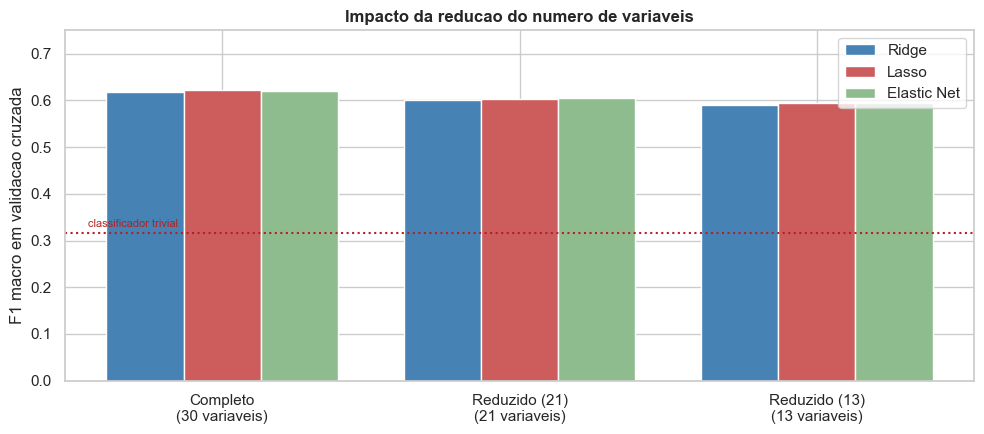

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
largura = 0.26
posicao = np.arange(len(CONJUNTOS))
for deslocamento, (lab, _), cor in zip([-largura, 0, largura], MODELOS,
                                       ['steelblue', 'indianred', 'darkseagreen']):
    valores = [resultados.loc[f'{nome} | {lab}', 'F1 macro (CV)'] for nome in CONJUNTOS]
    ax.bar(posicao + deslocamento, valores, largura, label=lab, color=cor)
ax.set_xticks(posicao)
ax.set_xticklabels([f'{n}\n({len(CONJUNTOS[n][0]) + len(CONJUNTOS[n][1])} variaveis)'
                    for n in CONJUNTOS])
ax.axhline(0.3158, ls=':', color='firebrick')
ax.text(-0.45, 0.33, 'classificador trivial', fontsize=8, color='firebrick')
ax.set_ylabel('F1 macro em validacao cruzada'); ax.set_ylim(0, 0.75)
ax.set_title('Impacto da reducao do numero de variaveis', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

**Conclusões:** A redução do número de variáveis tem um custo pequeno e progressivo.

O conjunto completo de 30 variáveis atinge 0.6232 de F1 macro em validação cruzada. Reduzindo para 21
variáveis, o melhor valor desce para 0.6051, uma perda de 0.018. Reduzindo para 13 variáveis, menos de
metade do original, desce para 0.5948, uma perda total de 0.028.

Um modelo com **43 por cento das variáveis conserva 95 por cento do desempenho**.
As três penalizações comportam-se de forma praticamente idêntica dentro de cada conjunto, o que é
esperado, pois depois de removidas as variáveis irrelevantes resta pouca diferença entre contrair
coeficientes e anulá-los.

O conjunto de 13 variáveis inclui `HbA1c_level`, `triglycerides`, `age` e `blood_pressure`, que a
análise exploratória tinha identificado como informativas. Inclui também `crp_level`, `plasma_value` e
`ldl_alternative`, que os testes estatísticos não tinham destacado. O caso de `ldl_alternative` merece
atenção, pois a análise exploratória concluiu tratar-se de uma permutação aleatória das linhas de
`ldl`, sem ligação ao paciente. A sua sobrevivência mostra que a penalização que otimiza o desempenho
não elimina necessariamente todo o ruído, e constitui um argumento para confrontar sempre a seleção
automática com a evidência estatística prévia.

## 8. Efeito do balanceamento das classes

Todos os modelos anteriores obtêm *accuracy* acima de 0.94 mas balanced accuracy próxima de 0.65. A
razão é que acertam quase sempre na classe maioritária e falham a minoritária, devido ao desiquilíbrio existente, com cerca de 90% dos registos numa única classe.

O parâmetro `class_weight='balanced'` pondera cada classe pelo inverso da sua frequência, obrigando o
modelo a dar importância às classes pequenas.

Esta comparação usa o algoritmo `lbfgs` com penalização L2, porque o `saga` não converge quando se
aplica `class_weight`.

In [9]:
def avaliar_cv_lbfgs(C, class_weight):
    """Mesma validacao cruzada manual, com o solver lbfgs e penalizacao L2."""
    pontuacoes = []
    for idx_treino, idx_validacao in cv.split(X_train, y_train):
        escala = StandardScaler()
        X_a_esc = escala.fit_transform(X_train.iloc[idx_treino])
        X_b_esc = escala.transform(X_train.iloc[idx_validacao])
        modelo = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=C, max_iter=10000,
                                    class_weight=class_weight,
                                    random_state=RANDOM_STATE)
        modelo.fit(X_a_esc, y_train.iloc[idx_treino])
        pontuacoes.append(f1_score(y_train.iloc[idx_validacao],
                                   modelo.predict(X_b_esc), average='macro'))
    return float(np.mean(pontuacoes))

comparacao_peso = []
previsoes = {}
for peso in (None, 'balanced'):
    melhor_C = max(GRELHA_C, key=lambda C: avaliar_cv_lbfgs(C, peso))
    f1_cv = avaliar_cv_lbfgs(melhor_C, peso)

    escala = StandardScaler()
    X_esc = escala.fit_transform(X_train)
    modelo = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=melhor_C,
                                max_iter=10000, class_weight=peso,
                                random_state=RANDOM_STATE).fit(X_esc, y_train)
    previsto = modelo.predict(escala.transform(X_test))
    recalls = recall_score(y_test, previsto, average=None, labels=classes)
    comparacao_peso.append({
        'class_weight': str(peso), 'C*': melhor_C, 'F1 macro (CV)': f1_cv,
        'accuracy': accuracy_score(y_test, previsto),
        'balanced acc': balanced_accuracy_score(y_test, previsto),
        **{f'recall {c}': r for c, r in zip(classes, recalls)}})
    previsoes[str(peso)] = previsto

pd.DataFrame(comparacao_peso).set_index('class_weight').round(4)

,C*,F1 macro (CV),accuracy,balanced acc,recall DI_HT,recall DI_HY,recall HT
class_weight,,,,,,,
None,1.5199,0.6185,0.9460,0.6539,0.1429,0.9911,0.8276
balanced,0.1874,0.6108,0.7640,0.7421,0.6667,0.7667,0.7931


=== sem balanceamento ===
              precision    recall  f1-score   support

       DI_HT     0.6000    0.1429    0.2308        21
       DI_HY     0.9571    0.9911    0.9738       450
          HT     0.8276    0.8276    0.8276        29

    accuracy                         0.9460       500
   macro avg     0.7949    0.6539    0.6774       500
weighted avg     0.9346    0.9460    0.9341       500

=== com class_weight='balanced' ===
              precision    recall  f1-score   support

       DI_HT     0.1157    0.6667    0.1972        21
       DI_HY     0.9914    0.7667    0.8647       450
          HT     0.7419    0.7931    0.7667        29

    accuracy                         0.7640       500
   macro avg     0.6163    0.7421    0.6095       500
weighted avg     0.9401    0.7640    0.8309       500



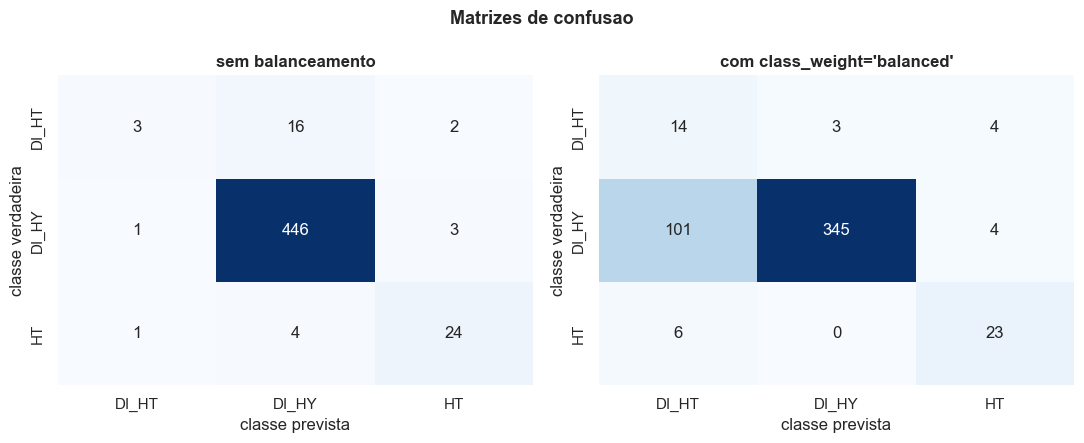

In [10]:
CONFIGURACOES = [('None', 'sem balanceamento'),
                 ('balanced', "com class_weight='balanced'")]

for rotulo, titulo in CONFIGURACOES:
    print(f'=== {titulo} ===')
    print(classification_report(y_test, previsoes[rotulo], labels=classes, digits=4))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for eixo, (rotulo, titulo) in zip(eixos, CONFIGURACOES):
    matriz = confusion_matrix(y_test, previsoes[rotulo], labels=classes)
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=classes, yticklabels=classes, ax=eixo)
    eixo.set_xlabel('classe prevista'); eixo.set_ylabel('classe verdadeira')
    eixo.set_title(titulo, weight='bold')
fig.suptitle('Matrizes de confusao', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

**Conclusões:** Sem compensação, o modelo atinge 0.9460 de *accuracy* mas apenas 0.14 de recall na classe `DI_HT`. Com `class_weight='balanced'`, o
recall de `DI_HT` sobe para 0.67 e a balanced accuracy de 0.6539 para 0.7421, enquanto a *accuracy*
desce para 0.7640.

A leitura é que o segundo modelo acerta menos vezes no total, mas distribui os acertos pelas três
classes. Sem compensação, das 21
ocorrências reais de `DI_HT` o modelo identifica apenas 3 e encaminha 16 para `DI_HY`. Com
compensação identifica 14, mas em contrapartida classifica erradamente 101 registos de `DI_HY` como
`DI_HT`. Por outras palavras, detetar mais 11 casos da classe minoritária custa cerca de uma centena
de falsos positivos.

Em ambas as configurações os erros concentram-se na separação entre `DI_HT` e `DI_HY`, as duas classes
cuja sobreposição a análise exploratória já tinha identificado.

O ganho de recall reflete-se num custo em precisão, que desce para cerca de 0.12 na classe
`DI_HT`. A configuração preferível depende do custo relativo dos erros, informação de
natureza clínica que o enunciado não fornece.

## 9. Discussão

**As três penalizações desempenham de forma equivalente.** As diferenças de F1 macro entre Ridge,
Lasso e Elastic Net ficam abaixo de 0.01 em todos os conjuntos testados, valor inferior à variação
entre partições da validação cruzada. A escolha entre elas não se justifica, neste problema, pelo
desempenho.

**O Ridge não tinha vantagem a oferecer.** A sua razão de ser é estabilizar coeficientes quando os
preditores estão correlacionados. A análise exploratória mostrou que, removidas as colunas
redundantes, as correlações entre variáveis são praticamente nulas, com fatores de inflação da
variância abaixo de 1.05. Em conjuntos de dados onde os preditores estão fortemente correlacionados, com fatores de
inflação na ordem das centenas, o Ridge supera claramente a solução não regularizada.

**A vantagem do Lasso está na interpretabilidade, não na exatidão.** É a única penalização que anula
coeficientes de forma sistemática, e é isso que permite construir os conjuntos reduzidos. O ganho não
aparece nas métricas, mas sim na possibilidade de obter um modelo com treze variáveis em vez de trinta.

**A seleção confirma a análise exploratória.** As variáveis que sobrevivem às penalizações mais fortes
incluem `HbA1c_level` e `triglycerides`, exatamente as que os testes estatísticos tinham apontado como
as mais discriminativas.

## 10. Referências

**Enunciado e dados**

- *Aprendizagem Automática (APRAU), Assignment*, ISEP, MEI, 2026/2027, versão 1.0, secção 5.
- `dataset_grupo_22.csv`, subconjunto de 2000 registos fornecido ao grupo 22.

**Aulas da unidade curricular** (Elsa Ferreira Gomes, ISEP, 2026/2027)

- *T5, Linear Model Selection and Regularization: Ridge Regression, the Lasso and Elastic Net*,
  incluindo a secção sobre regularização aplicada à classificação.
- *TP5, Example: Ridge, Lasso and Elastic net Regression*, ficha prática consultada.
- *T4, Evaluation and Resampling*, para a validação cruzada estratificada.
- *Classification Metrics: Confusion Matrix and Beyond*, para a escolha das métricas.

**Bibliografia**

- James, G., Witten, D., Hastie, T., Tibshirani, R., *An Introduction to Statistical Learning with
  Python*, capítulo 6.

**Trabalho anterior do grupo**

- `notebooks/EDA_version3.ipynb`, de onde provêm a remoção das colunas redundantes e as expectativas
  sobre quais as variáveis informativas.

**Bibliotecas**

- pandas, NumPy, Matplotlib, seaborn e scikit-learn.